# Question 1

### Link functions

1a: Broadly speaking, the link functions from the unconstrained vector in $\mathbb{R}^2$ to $f_{\mu}$ and $f_{\sigma}$ need to be differentiable (further, gradients shouldn't vanish or explode), in addition to mapping to the desired ranges.

$f_{\mu}$ can be any real, so we can just take the identity as our link function.

Meanwhile, $f_{\sigma}$ needs to be positive, so we need our link function to take $\mathbb{R}$ to $\mathbb{R}^+$. One link function that would work for this is $\log \left( 1 + e^z \right)$. It's always positive, and for large $z$, $\log \left( 1 + e^z \right) \approx z$. We discussed this on page 75 of the L2 slide deck.

### Loss function

1b: We assume the data comes from a normal distribution. The density of this distribution is given by

\begin{equation*}
p(y_i \mid \mu_i, \sigma_i) = \frac{1}{\sqrt{2 \pi \sigma_i^2}} \exp \left( - \frac{(y_i- \mu_i)^2} {2 \sigma_i^2} \right)
\end{equation*}

Computing the MLE with log likelihood (since the data is assumed iid), we get an estimator

\begin{align*}
\hat{\theta} &= \operatorname*{arg\,max}_\theta \sum_{i=1}^n \log p(y_i \mid f_{\mu}(X_i ; \theta), f_{\sigma}(X_i ; \theta)) \\
&= \operatorname*{arg\,max}_\theta \sum_{i=1}^n \left[ \log \left(\frac{1}{\sqrt{2 \pi}} \right) + \log \left(\frac{1}{f_{\sigma}(X_i ; \theta)} \right) - \left ( \frac{(y_i - f_{\mu}(X_i ; \theta))^2}{2 f_{\sigma}(X_i ; \theta)^2} \right) \right] \\
&= \operatorname*{arg\,max}_\theta \sum_{i=1}^n \left[ - \log f_{\sigma}(X_i ; \theta) - \left ( \frac{(y_i - f_{\mu}(X_i ; \theta))^2}{2 f_{\sigma}(X_i ; \theta)^2} \right) \right] \\
&= \operatorname*{arg\,min}_\theta \sum_{i=1}^n \left[ \log f_{\sigma}(X_i ; \theta) + \left ( \frac{(y_i - f_{\mu}(X_i ; \theta))^2}{2 f_{\sigma}(X_i ; \theta)^2} \right) \right]
\end{align*}

We can then minimize this using SGD. The "loss function" here is the sum of the "losses" at each point. Multiplying by a constant, we can also take
\begin{equation*}
\mathcal{L} = \frac{1}{n} \sum_{i=1}^n \left[ \log f_{\sigma}(X_i ; \theta) + \left ( \frac{(y_i - f_{\mu}(X_i ; \theta))^2}{2 f_{\sigma}(X_i ; \theta)^2} \right) \right]
\end{equation*}
as the loss to minimize.

## Taxi trips model

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

taxi = pd.read_parquet("data/taxi_trips.parquet")
print("shape:", taxi.shape)
taxi.head(1)

shape: (523554, 8)


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
187173,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855


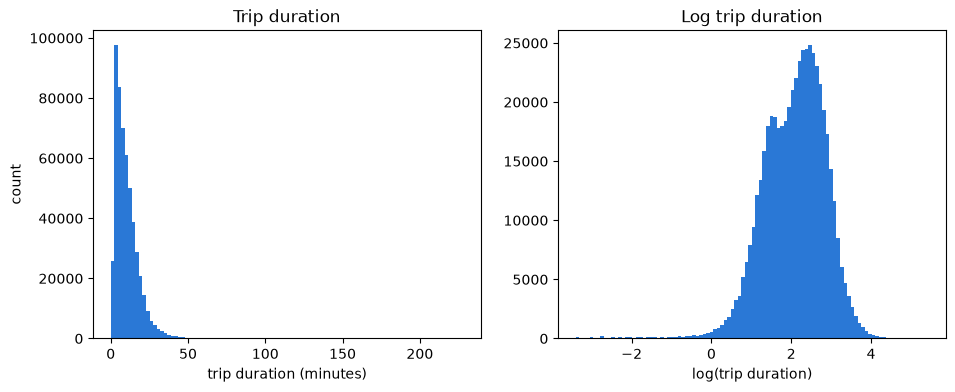

0.001     0.083440
0.010     1.083824
0.500     8.631456
0.990    37.124424
0.999    63.269640
Name: trip_duration, dtype: float64


In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(taxi["trip_duration"], bins=100, color="#2a78d6")
ax1.set_xlabel("trip duration (minutes)")
ax1.set_ylabel("count")
ax1.set_title("Trip duration")

ax2.hist(np.log(taxi["trip_duration"]), bins=100, color="#2a78d6")
ax2.set_xlabel("log(trip duration)")
ax2.set_title("Log trip duration")

plt.show()
print(taxi["trip_duration"].quantile([0.001, 0.01, 0.5, 0.99, 0.999]))

80/10/10 training/validation/test split. Validation data is used to preemptively stop MLP training to prevent overfitting.

In [3]:
from sklearn.model_selection import train_test_split

feature_cols = [c for c in taxi.columns if c != "trip_duration"]
X = taxi[feature_cols].values
y = taxi["trip_duration"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=0)

print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

train: (418843, 7) | val: (52355, 7) | test: (52356, 7)


In [4]:
from scipy import stats

def evaluate(name, y, mu, sigma, scale):
    """Score a model's predictive distribution, in minutes.
    y: true durations (minutes). mu, sigma: model outputs, in minutes if scale="raw",
    or on the log scale if scale="log". Constants are fine for mu and sigma."""
    y = np.asarray(y, dtype=np.float64)
    mu = np.asarray(mu, dtype=np.float64) * np.ones_like(y)
    sigma = np.asarray(sigma, dtype=np.float64) * np.ones_like(y)

    if scale == "raw":
        target = y
        median_pred = mu
        mean_pred = mu
        nll = -stats.norm.logpdf(target, mu, sigma).mean()
    elif scale == "log":
        target = np.log(y)
        median_pred = np.exp(mu)
        mean_pred = np.exp(mu + sigma**2 / 2)
        nll = -stats.norm.logpdf(target, mu, sigma).mean() + target.mean()   # + log(y): convert to minutes
    else:
        raise ValueError("scale must be 'raw' or 'log'")

    z = np.abs(target - mu) / sigma     # how many sigmas off each trip was
    return {
        "model": name,
        "NLL (minutes)": nll,
        "MAE": np.abs(y - median_pred).mean(),
        "RMSE": np.sqrt(((y - median_pred) ** 2).mean()),   # median: the log-normal mean is unstable for large sigma
        "50% coverage": (z <= stats.norm.ppf(0.75)).mean(),
        "90% coverage": (z <= stats.norm.ppf(0.95)).mean(),
    }

### Baselines

I'm training two sets of models: to predict raw minutes values and to predict log(minutes). Reasons to use the log version include the fact it that better captures the distribution of rides (more even density) and the normal will only contain positive trip times in its range. Log model outputs are converted back into minutes to enable easier interpretation and comparison.

Model classes:
- Constant
- Linear by coordinates
- Linear with a distance metric added (computed from pickup and dropoff coordinates)

In [5]:
results = {}

def record(row):
    """Store a model's metrics, replacing any earlier entry with the same name."""
    results[row["model"]] = row

y_train64 = y_train.astype(np.float64)
log_y_train = np.log(y_train64)

record(evaluate("constant (raw)", y_val, y_train64.mean(), y_train64.std(), "raw"))
record(evaluate("constant (log)", y_val, log_y_train.mean(), log_y_train.std(), "log"))

In [6]:
from sklearn.linear_model import LinearRegression

# Linear mean, constant sigma (the residual sd)
lin_raw = LinearRegression().fit(X_train, y_train64)
sd_raw = (y_train64 - lin_raw.predict(X_train)).std()
record(evaluate("linear (raw)", y_val, lin_raw.predict(X_val), sd_raw, "raw"))

lin_log = LinearRegression().fit(X_train, log_y_train)
sd_log = (log_y_train - lin_log.predict(X_train)).std()
record(evaluate("linear (log)", y_val, lin_log.predict(X_val), sd_log, "log"))

pd.DataFrame(list(results.values())).set_index("model").round(3)

,NLL (minutes),MAE,RMSE,50% coverage,90% coverage
model,,,,,
constant (raw),3.458,5.664,7.684,0.522,0.943
constant (log),3.244,5.510,8.032,0.487,0.926
linear (raw),3.430,5.545,7.470,0.536,0.938
linear (log),3.234,5.435,7.902,0.489,0.930


In [7]:
col = {name: i for i, name in enumerate(feature_cols)}

def distance_features(X):
    """Hand-made distance features from the standardized coordinates, plus the time features.
    Give log distance as an extra parameter."""
    d_lon = X[:, col["dropoff_longitude"]] - X[:, col["pickup_longitude"]]
    d_lat = X[:, col["dropoff_latitude"]] - X[:, col["pickup_latitude"]]
    dist = np.sqrt(d_lon**2 + d_lat**2)
    time_cols = [col["min_of_day"], col["day_of_week"], col["day_of_year"]]
    return np.column_stack([np.abs(d_lon), np.abs(d_lat), dist, np.log1p(dist), X[:, time_cols]])

In [8]:
Xd_train = distance_features(X_train)
Xd_val = distance_features(X_val)

dist_raw = LinearRegression().fit(Xd_train, y_train64)
sd_dist_raw = (y_train64 - dist_raw.predict(Xd_train)).std()
record(evaluate("distance-linear (raw)", y_val, dist_raw.predict(Xd_val), sd_dist_raw, "raw"))

dist_log = LinearRegression().fit(Xd_train, log_y_train)
sd_dist_log = (log_y_train - dist_log.predict(Xd_train)).std()
record(evaluate("distance-linear (log)", y_val, dist_log.predict(Xd_val), sd_dist_log, "log"))

pd.DataFrame(list(results.values())).set_index("model").round(3)

,NLL (minutes),MAE,RMSE,50% coverage,90% coverage
model,,,,,
constant (raw),3.458,5.664,7.684,0.522,0.943
constant (log),3.244,5.510,8.032,0.487,0.926
linear (raw),3.430,5.545,7.470,0.536,0.938
linear (log),3.234,5.435,7.902,0.489,0.930
distance-linear (raw),3.018,3.375,4.950,0.639,0.928
distance-linear (log),2.833,3.474,5.492,0.572,0.924


### MLP

In [9]:
import copy
import torch.nn as nn

class MeanStdMLP(nn.Module):
    """MLP with two outputs: mu (identity link) and sigma (softplus link + floor)."""
    def __init__(self, n_features, hidden=(64, 64), eps=1e-4):
        super().__init__()
        layers = []
        d = n_features
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, 2))
        self.net = nn.Sequential(*layers)
        self.eps = eps

    def forward(self, x):
        out = self.net(x)                                       # shape [n, 2]: (z1, z2)
        mu = out[:, 0]                                          # f_mu = z1
        sigma = nn.functional.softplus(out[:, 1]) + self.eps    # f_sigma = softplus(z2) + eps
        return mu, sigma


def gaussian_nll(y, mu, sigma):
    """The loss from 1b: mean of log(sigma) + (y - mu)^2 / (2 sigma^2)."""
    return (torch.log(sigma) + (y - mu) ** 2 / (2 * sigma ** 2)).mean()


In [10]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)

Parameters:
- Layers: 7 - 64 - 64 - 2
- Batch size = 1024
- Patience = 10 (amount of epochs to continue running if validation performance stops improving)
- Adam optimizer with learning rate 1e-3

In [11]:
def train_mlp(scale, hidden=(64, 64), lr=1e-3, batch_size=1024, max_epochs=60, patience=10, seed=0):
    """Train a MeanStdMLP on raw or log durations with early stopping on validation NLL.
    Returns the model (best weights), the target's mean and sd (for un-standardizing), and the history."""
    torch.manual_seed(seed)

    # Target on the chosen scale, then standardized using TRAINING statistics
    t_train = np.log(y_train64) if scale == "log" else y_train64
    t_val = np.log(y_val.astype(np.float64)) if scale == "log" else y_val.astype(np.float64)
    t_mean, t_sd = t_train.mean(), t_train.std()
    yt_train = torch.tensor((t_train - t_mean) / t_sd, dtype=torch.float32)
    yt_val = torch.tensor((t_val - t_mean) / t_sd, dtype=torch.float32)

    model = MeanStdMLP(X_train_t.shape[1], hidden=hidden)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    n = len(X_train_t)
    best_val, best_state, epochs_without_improvement = np.inf, None, 0
    history = {"train": [], "val": []}

    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(n)
        running = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            mu, sigma = model(X_train_t[idx])
            loss = gaussian_nll(yt_train[idx], mu, sigma)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item() * len(idx)

        model.eval()
        with torch.no_grad():
            mu, sigma = model(X_val_t)
            val_loss = gaussian_nll(yt_val, mu, sigma).item()

        history["train"].append(running / n)
        history["val"].append(val_loss)

        if val_loss < best_val - 1e-4:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    model.load_state_dict(best_state)
    print(f"{scale}: stopped after {epoch + 1} epochs; best validation NLL {best_val:.4f}")
    return model, t_mean, t_sd, history

In [12]:
def predict_mu_sigma(model, X_t, t_mean, t_sd):
    """mu and sigma on the target's own scale (minutes or log-minutes), as NumPy arrays."""
    model.eval()
    with torch.no_grad():
        mu, sigma = model(X_t)
    return mu.numpy() * t_sd + t_mean, sigma.numpy() * t_sd


def plot_history(history, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    epochs = range(1, len(history["train"]) + 1)
    ax.plot(epochs, history["train"], color="#2a78d6", linewidth=2, label="train")
    ax.plot(epochs, history["val"], color="#eb6834", linewidth=2, label="validation")
    ax.set_xlabel("epoch")
    ax.set_ylabel("Gaussian NLL (standardized target)")
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    plt.show()



raw: stopped after 60 epochs; best validation NLL -0.3662


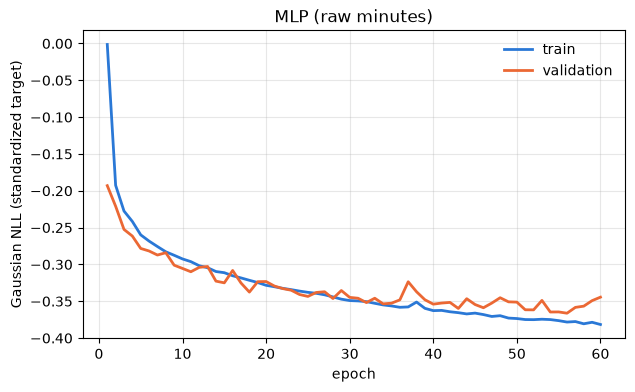

In [13]:
mlp_raw, raw_mean, raw_sd, hist_raw = train_mlp("raw")
plot_history(hist_raw, "MLP (raw minutes)")

mu_raw, sigma_raw = predict_mu_sigma(mlp_raw, X_val_t, raw_mean, raw_sd)
record(evaluate("MLP (raw)", y_val, mu_raw, sigma_raw, "raw"))

log: stopped after 60 epochs; best validation NLL -0.4185


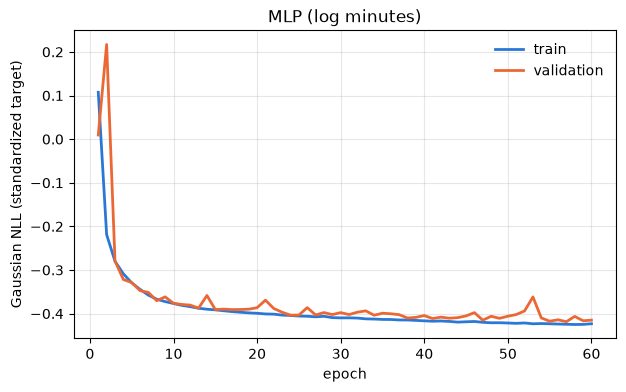

,NLL (minutes),MAE,RMSE,50% coverage,90% coverage
model,,,,,
constant (raw),3.458,5.664,7.684,0.522,0.943
constant (log),3.244,5.510,8.032,0.487,0.926
linear (raw),3.430,5.545,7.470,0.536,0.938
linear (log),3.234,5.435,7.902,0.489,0.930
distance-linear (raw),3.018,3.375,4.950,0.639,0.928
distance-linear (log),2.833,3.474,5.492,0.572,0.924
MLP (raw),2.602,2.419,3.895,0.582,0.930
MLP (log),2.321,2.306,3.845,0.517,0.902


In [14]:
mlp_log, log_mean, log_sd, hist_log = train_mlp("log")
plot_history(hist_log, "MLP (log minutes)")

mu_log, sigma_log = predict_mu_sigma(mlp_log, X_val_t, log_mean, log_sd)
record(evaluate("MLP (log)", y_val, mu_log, sigma_log, "log"))

pd.DataFrame(list(results.values())).set_index("model").round(3)

### Evaluating using the test set

In [15]:
Xd_test = distance_features(X_test)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

mu_raw_test, sigma_raw_test = predict_mu_sigma(mlp_raw, X_test_t, raw_mean, raw_sd)
mu_log_test, sigma_log_test = predict_mu_sigma(mlp_log, X_test_t, log_mean, log_sd)

test_results = [
    evaluate("constant (raw)", y_test, y_train64.mean(), y_train64.std(), "raw"),
    evaluate("constant (log)", y_test, log_y_train.mean(), log_y_train.std(), "log"),
    evaluate("linear (raw)", y_test, lin_raw.predict(X_test), sd_raw, "raw"),
    evaluate("linear (log)", y_test, lin_log.predict(X_test), sd_log, "log"),
    evaluate("distance-linear (raw)", y_test, dist_raw.predict(Xd_test), sd_dist_raw, "raw"),
    evaluate("distance-linear (log)", y_test, dist_log.predict(Xd_test), sd_dist_log, "log"),
    evaluate("MLP (raw)", y_test, mu_raw_test, sigma_raw_test, "raw"),
    evaluate("MLP (log)", y_test, mu_log_test, sigma_log_test, "log"),
]
pd.DataFrame(test_results).set_index("model").round(3)

,NLL (minutes),MAE,RMSE,50% coverage,90% coverage
model,,,,,
constant (raw),3.464,5.685,7.727,0.520,0.942
constant (log),3.242,5.514,8.077,0.485,0.928
linear (raw),3.437,5.583,7.523,0.533,0.937
linear (log),3.232,5.443,7.934,0.487,0.931
distance-linear (raw),3.027,3.391,4.992,0.639,0.927
distance-linear (log),2.831,3.486,5.527,0.571,0.924
MLP (raw),2.752,2.418,3.904,0.583,0.929
MLP (log),2.322,2.305,3.851,0.514,0.903


In [16]:
val_nll = results["MLP (raw)"]["NLL (minutes)"]

y_test64 = y_test.astype(np.float64)
nll_rows = -stats.norm.logpdf(y_test64, mu_raw_test, sigma_raw_test)
test_nll = nll_rows.mean()

# The 5 trips with the largest NLL
order = np.argsort(nll_rows)          # positions sorted from smallest to largest NLL
worst = order[::-1][:5]               # reverse it, then take the first 5
test_nll_without_worst = np.delete(nll_rows, worst).mean()

print(f"validation NLL:            {val_nll:.3f}")
print(f"test NLL:                  {test_nll:.3f}")
print(f"difference (test - val):   {test_nll - val_nll:+.3f}")
print(f"test NLL without worst 5:  {test_nll_without_worst:.3f}")

pd.DataFrame({
    "actual (min)": y_test[worst],
    "predicted mu": mu_raw_test[worst],
    "predicted sigma": sigma_raw_test[worst],
    "trip NLL": nll_rows[worst],
}).round(2)

validation NLL:            2.602
test NLL:                  2.752
difference (test - val):   +0.149
test NLL without worst 5:  2.581


,actual (min),predicted mu,predicted sigma,trip NLL
0,173.339996,3.50,1.51,6368.17
1,113.500000,5.26,2.32,1085.92
2,96.250000,9.69,2.44,631.07
3,99.870003,13.14,2.85,465.16
4,58.419998,3.13,1.96,400.11


Likely, the test set NLL is skewed due to these very irregular / improbable data points.

In [17]:
preds = {
    "constant (raw)":        (y_train64.mean(), y_train64.std(), "raw"),
    "constant (log)":        (log_y_train.mean(), log_y_train.std(), "log"),
    "distance-linear (raw)": (dist_raw.predict(Xd_test), sd_dist_raw, "raw"),
    "distance-linear (log)": (dist_log.predict(Xd_test), sd_dist_log, "log"),
    "MLP (raw)":             (mu_raw_test, sigma_raw_test, "raw"),
    "MLP (log)":             (mu_log_test, sigma_log_test, "log"),
}

family_color = {"constant": "#8c8c8c", "distance-linear": "#2a78d6", "MLP": "#eb6834"}

def style(name):
    """Color by model family, line style by scale: solid = log, dashed = raw."""
    family, scale = name.split(" (")
    return {"color": family_color[family], "linestyle": "-" if scale.startswith("log") else "--"}

levels = np.linspace(0.05, 0.95, 19)

def coverage_curve(y, mu, sigma, scale):
    """For each nominal level p, the fraction of trips inside the model's central p-interval."""
    y = np.asarray(y, dtype=np.float64)
    target = np.log(y) if scale == "log" else y
    z = np.abs(target - mu) / sigma
    return np.array([(z <= stats.norm.ppf(0.5 + p / 2)).mean() for p in levels])

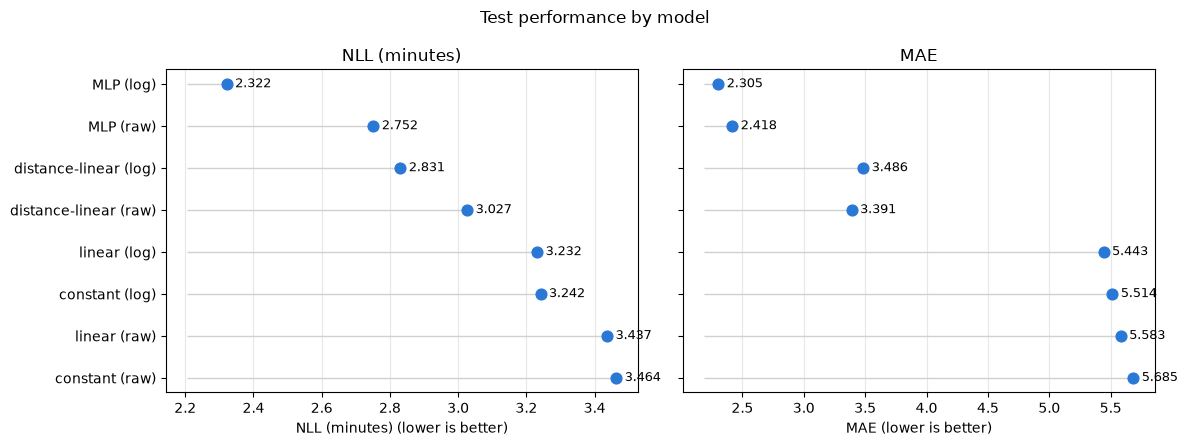

In [18]:
test_table = pd.DataFrame(test_results).set_index("model").sort_values("NLL (minutes)", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, metric in zip(axes, ["NLL (minutes)", "MAE"]):
    ypos = np.arange(len(test_table))
    ax.hlines(ypos, test_table[metric].min() * 0.95, test_table[metric], color="#d0d0d0", linewidth=1)
    ax.scatter(test_table[metric], ypos, s=60, color="#2a78d6", zorder=3)
    for yp, v in zip(ypos, test_table[metric]):
        ax.annotate(f"{v:.3f}", (v, yp), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_yticks(ypos)
    ax.set_yticklabels(test_table.index)
    ax.set_xlabel(metric + " (lower is better)")
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Test performance by model")
fig.tight_layout()
plt.show()

The MLP log model performs best on both metrics!

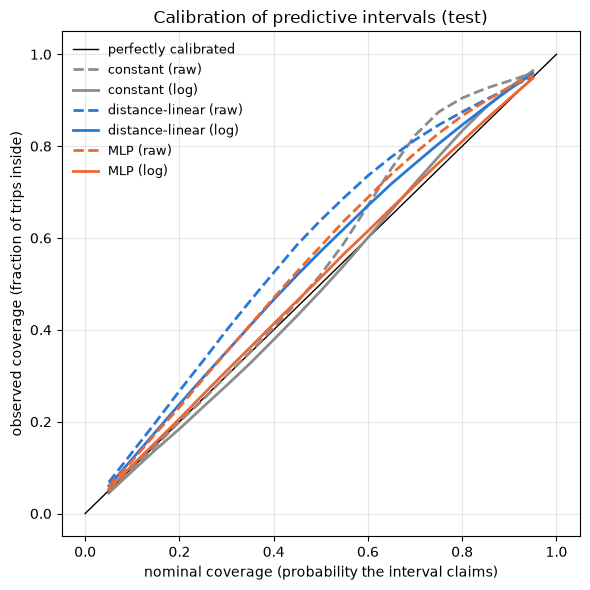

In [19]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="black", linewidth=1, label="perfectly calibrated")
for name, (mu, sigma, scale) in preds.items():
    ax.plot(levels, coverage_curve(y_test, mu, sigma, scale), linewidth=2, label=name, **style(name))
ax.set_xlabel("nominal coverage (probability the interval claims)")
ax.set_ylabel("observed coverage (fraction of trips inside)")
ax.set_title("Calibration of predictive intervals (test)")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

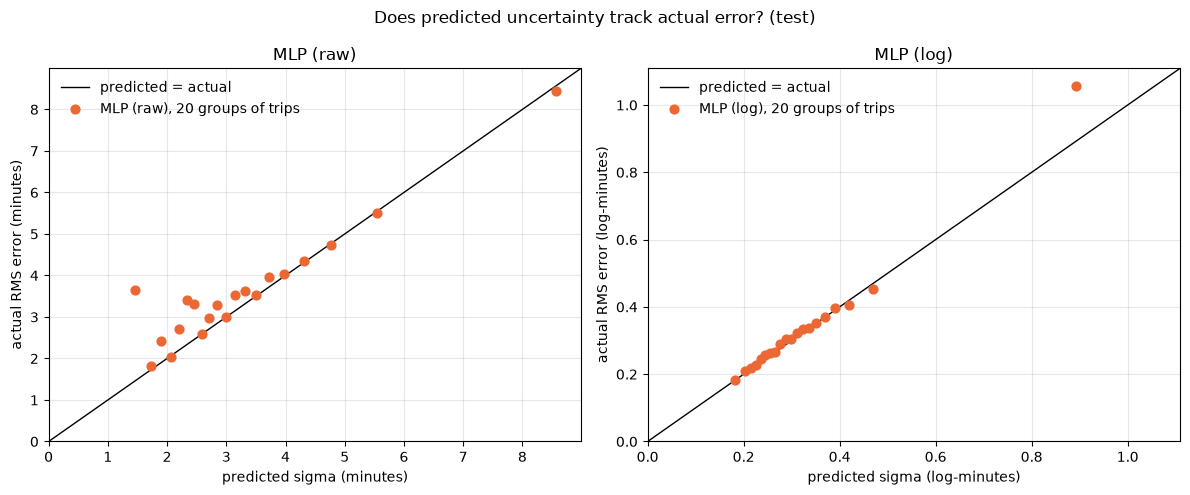

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, mu, sigma, scale, unit) in zip(axes, [
        ("MLP (raw)", mu_raw_test, sigma_raw_test, "raw", "minutes"),
        ("MLP (log)", mu_log_test, sigma_log_test, "log", "log-minutes")]):
    target = np.log(y_test) if scale == "log" else y_test
    resid = target - mu
    bins = pd.qcut(sigma, 20, labels=False)
    g = pd.DataFrame({"bin": bins, "sigma": sigma, "sq": resid**2}).groupby("bin").mean()
    pred_sd, actual_sd = g["sigma"], np.sqrt(g["sq"])

    lim = [0, max(pred_sd.max(), actual_sd.max()) * 1.05]
    ax.plot(lim, lim, color="black", linewidth=1, label="predicted = actual")
    ax.scatter(pred_sd, actual_sd, s=40, color="#eb6834", zorder=3, label=f"{name}, 20 groups of trips")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel(f"predicted sigma ({unit})")
    ax.set_ylabel(f"actual RMS error ({unit})")
    ax.set_title(name)
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
fig.suptitle("Does predicted uncertainty track actual error? (test)")
fig.tight_layout()
plt.show()

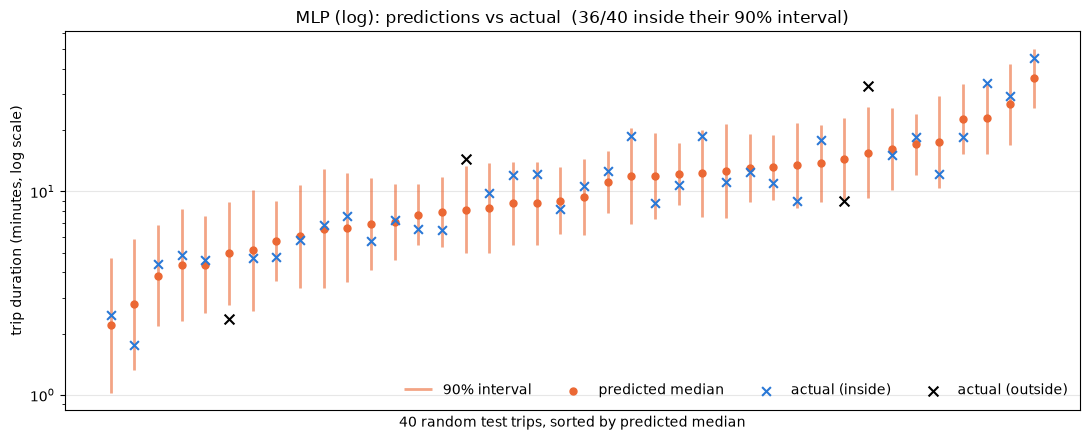

In [21]:
rng = np.random.default_rng(1)
idx = rng.choice(len(y_test), size=40, replace=False)
idx = idx[np.argsort(np.exp(mu_log_test[idx]))]

med = np.exp(mu_log_test[idx])
lo = np.exp(mu_log_test[idx] - 1.645 * sigma_log_test[idx])
hi = np.exp(mu_log_test[idx] + 1.645 * sigma_log_test[idx])
inside = (y_test[idx] >= lo) & (y_test[idx] <= hi)

fig, ax = plt.subplots(figsize=(11, 4.5))
xpos = np.arange(len(idx))
ax.vlines(xpos, lo, hi, color="#eb6834", linewidth=2, alpha=0.6, label="90% interval")
ax.scatter(xpos, med, color="#eb6834", s=25, zorder=3, label="predicted median")
ax.scatter(xpos[inside], y_test[idx][inside], marker="x", color="#2a78d6", s=40, zorder=4, label="actual (inside)")
ax.scatter(xpos[~inside], y_test[idx][~inside], marker="x", color="black", s=50, zorder=4, label="actual (outside)")
ax.set_yscale("log")
ax.set_xticks([])
ax.set_xlabel("40 random test trips, sorted by predicted median")
ax.set_ylabel("trip duration (minutes, log scale)")
ax.set_title(f"MLP (log): predictions vs actual  ({inside.sum()}/{len(idx)} inside their 90% interval)")
ax.legend(frameon=False, ncol=4, loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Probability that a given trip will take less than 45 minutes

We use the CDF of the normal that we get from the mean and standard deviation that our model gives:

\begin{equation*}
P(Y < 45 \mid x) = \Phi\!\left(\frac{45 - f_\mu(x)}{f_\sigma(x)}\right)
\end{equation*}

For the log version, this becomes

\begin{equation*}
P(Y < 45 \mid x) = P(\log Y < \log 45 \mid x) = \Phi\!\left(\frac{\log 45 - \mu}{\sigma}\right)
\end{equation*}

In [22]:
THRESHOLD = 45

def prob_under(threshold, mu, sigma, scale):
    """P(Y < threshold | x) from each trip's normal predictive distribution
    (normal on the log scale for log models)."""
    t = np.log(threshold) if scale == "log" else threshold
    return stats.norm.cdf((t - mu) / sigma)


p_raw_test = prob_under(THRESHOLD, mu_raw_test, sigma_raw_test, "raw")
p_log_test = prob_under(THRESHOLD, mu_log_test, sigma_log_test, "log")

print("fraction of training trips under 45 min:", (y_train < THRESHOLD).mean().round(4))
pd.DataFrame({
    "actual (min)": y_test[:8],
    "raw MLP: mu ± sigma": [f"{m:.1f} ± {s:.1f}" for m, s in zip(mu_raw_test[:8], sigma_raw_test[:8])],
    "P(<45), raw MLP": p_raw_test[:8],
    "P(<45), log MLP": p_log_test[:8],
}).round(4)

fraction of training trips under 45 min: 0.9956


,actual (min),raw MLP: mu ± sigma,"P(<45), raw MLP","P(<45), log MLP"
0,17.5921,12.9 ± 3.6,1.0,1.0
1,13.6117,10.9 ± 4.1,1.0,1.0
2,13.3619,12.2 ± 3.2,1.0,1.0
3,8.6981,7.8 ± 1.9,1.0,1.0
4,19.7071,10.1 ± 3.2,1.0,1.0
5,7.7153,8.0 ± 3.8,1.0,1.0
6,9.4144,5.0 ± 2.3,1.0,1.0
7,14.0447,8.8 ± 2.2,1.0,1.0


In [23]:
def binary_scores(name, y_minutes, p_under):
    """Score predicted probabilities of the event 'trip < THRESHOLD minutes'."""
    outcome = (np.asarray(y_minutes) < THRESHOLD).astype(np.float64)   # 1 if under the threshold
    p = np.asarray(p_under, dtype=np.float64) * np.ones_like(outcome)
    p_clip = np.clip(p, 1e-7, 1 - 1e-7)                                # for log-loss only

    return {
        "model": name,
        "Brier": np.mean((p - outcome) ** 2),
        "log-loss": -np.mean(outcome * np.log(p_clip) + (1 - outcome) * np.log(1 - p_clip)),
        "accuracy (p >= 0.5)": np.mean((p >= 0.5) == (outcome == 1)),
        "long trips caught": int(np.sum((p < 0.5) & (outcome == 0))),
        "false alarms": int(np.sum((p < 0.5) & (outcome == 1))),
    }

In [24]:
n_long = int((y_test >= THRESHOLD).sum())
print(f"test trips: {len(y_test)}, of which {n_long} took {THRESHOLD}+ minutes")

base_rate = (y_train < THRESHOLD).mean()
prob_results = [binary_scores(f"base rate (always {base_rate:.4f})", y_test, base_rate)]

for name, (mu, sigma, scale) in preds.items():
    prob_results.append(binary_scores(name, y_test, prob_under(THRESHOLD, mu, sigma, scale)))

pd.DataFrame(prob_results).set_index("model").round(4)

test trips: 52356, of which 234 took 45+ minutes


,Brier,log-loss,accuracy (p >= 0.5),long trips caught,false alarms
model,,,,,
base rate (always 0.9956),0.0044,0.0286,0.9955,0,0
constant (raw),0.0045,0.0553,0.9955,0,0
constant (log),0.0045,0.0325,0.9955,0,0
distance-linear (raw),0.0038,0.0297,0.9955,2,4
distance-linear (log),0.0063,0.0304,0.9954,0,5
MLP (raw),0.0031,0.0185,0.9962,72,38
MLP (log),0.0030,0.0162,0.9964,68,22


Of the models, only the MLP ones actually catch long trips! Accuracy doesn't distinguish the models though, because so few of the trips are actually over 45 minutes. However, the proper scoring rules, unlike accuracy, are better for the MLP models, meaning that the specific probabilities they assign to rides being over 45 minutes better match when they actually take that long.